In [1]:
import pandas as pd 
df = pd.read_csv('gossipcop_bal.csv') 

from sklearn.model_selection import train_test_split 
X_train_text, X_test_text, y_train, y_test = train_test_split( df['title'], df['label'], test_size=0.2, random_state=42 )

Device: cuda
GPU   : NVIDIA GeForce GTX 1650
VRAM  : 4.3 GB
  FAKE NEWS DETECTION — RoBERTa FINE-TUNING

Loading roberta-base…


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Total params    : 124,647,170
  Trainable params: 124,647,170

  Total opt steps : 2605
  Warmup steps    : 156

─────────────────────────────────────────────────────────────────
  TRAINING  (5 epochs max, patience=2)
─────────────────────────────────────────────────────────────────


Epoch 1/5 [Training]:   0%|          | 0/521 [00:00<?, ?it/s]

Epoch 1/5 [Validation]:   0%|          | 0/131 [00:00<?, ?it/s]

...

Epoch 4/5 [Training]:   0%|          | 0/521 [00:00<?, ?it/s]

Epoch 4/5 [Validation]:   0%|          | 0/131 [00:00<?, ?it/s]

  Epoch  4/5 | Train Loss: 0.2055  Val Loss: 0.6031 | Train Acc: 0.7945  Val Acc: 0.8136 | Time: 1888s
    No improvement (2/2)

  Early stopping triggered at epoch 4.

  Training complete in 7555.9s  (125.9 min)
  Best epoch: 2  (val_loss=0.4182)

Loading best checkpoint from epoch 2…

─────────────────────────────────────────────────────────────────
  FINAL EVALUATION ON TEST SET
─────────────────────────────────────────────────────────────────


Validation:   0%|          | 0/131 [00:00<?, ?it/s]


  Accuracy   : 0.8155
  Precision  : 0.8166  (macro)
  Recall     : 0.8162  (macro)
  F1 (macro) : 0.8155
  F1 (binary): 0.8138
  MCC        : 0.6329
  Kappa      : 0.6314
  AUC-ROC    : 0.8989
  Avg Prec   : 0.9067

Classification Report:
              precision    recall  f1-score   support

        Fake       0.79      0.85      0.82      1014
        Real       0.84      0.79      0.81      1067

    accuracy                           0.82      2081
   macro avg       0.82      0.82      0.82      2081
weighted avg       0.82      0.82      0.82      2081


─────────────────────────────────────────────────────────────────
  GENERATING PLOTS
─────────────────────────────────────────────────────────────────

  [Saved] plotR1_training_curves.png
  [Saved] plotR2_confusion_matrix.png
  [Saved] plotR3_roc_pr.png
  [Saved] plotR4_per_class_metrics.png
  [Saved] plotR5_prob_distribution.png
  [Saved] plotR6_threshold_analysis.png
  [Saved] plotR9_misclassification.png
  [Skip] comparison

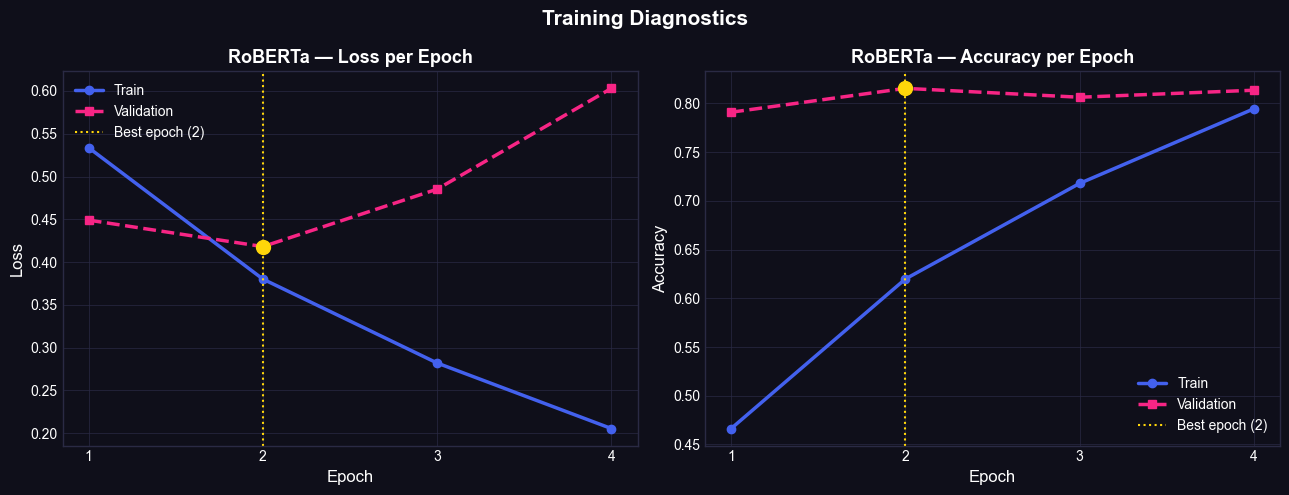

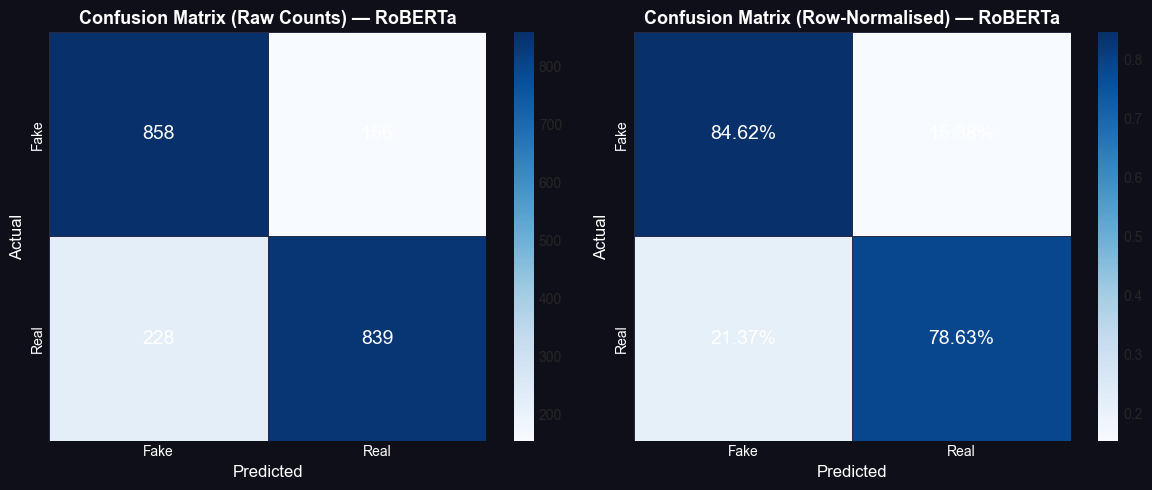

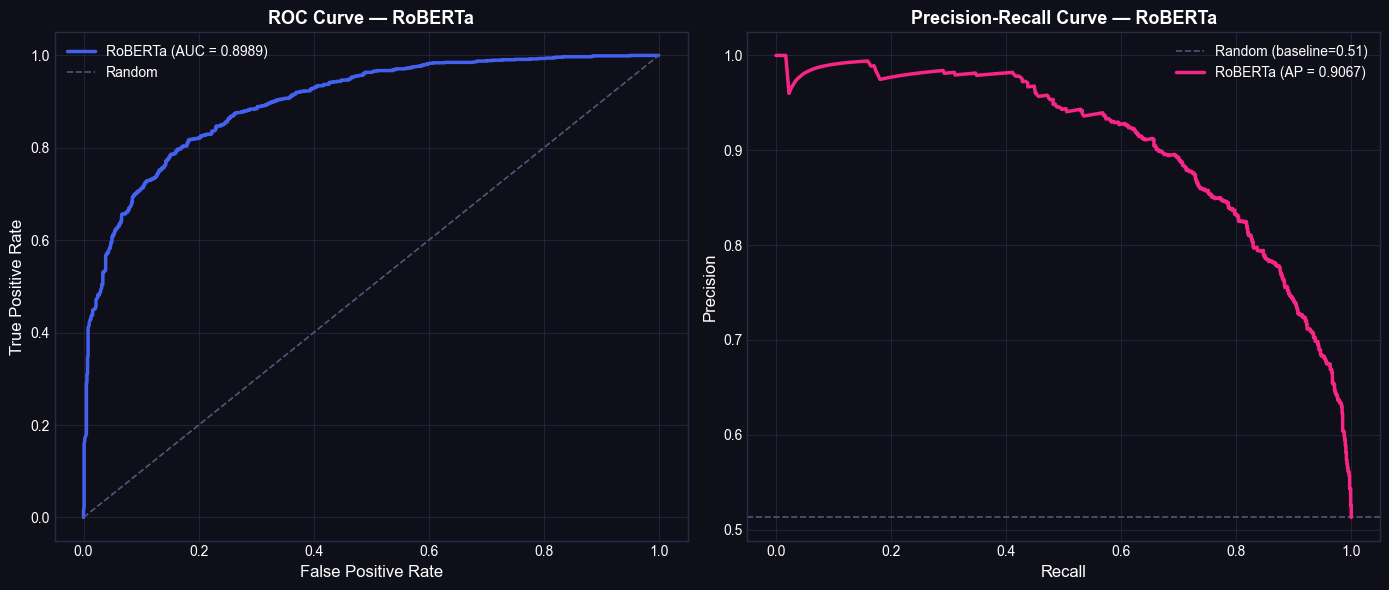

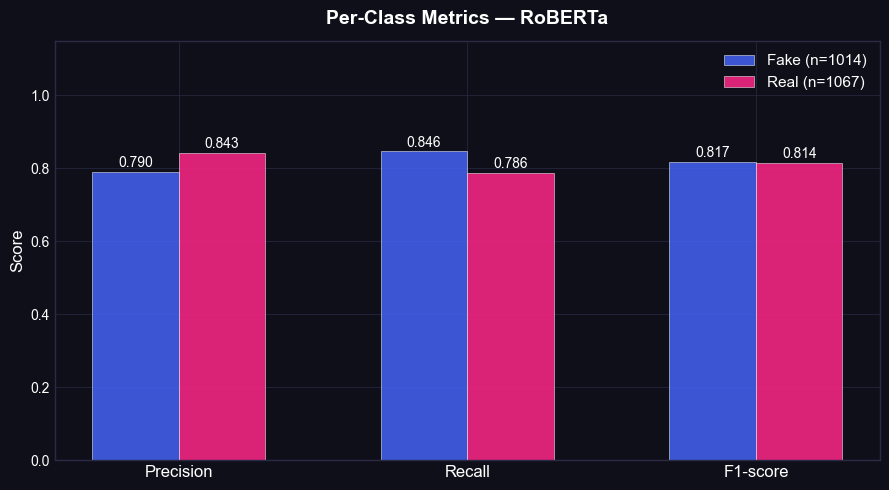

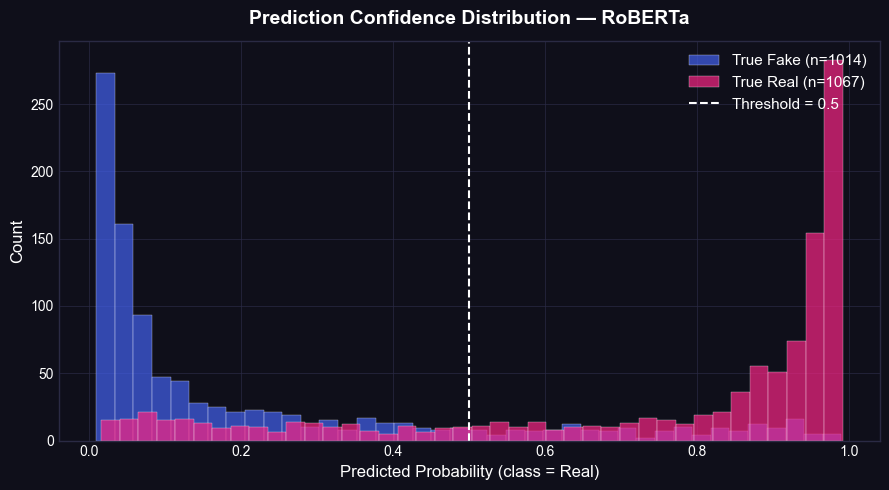

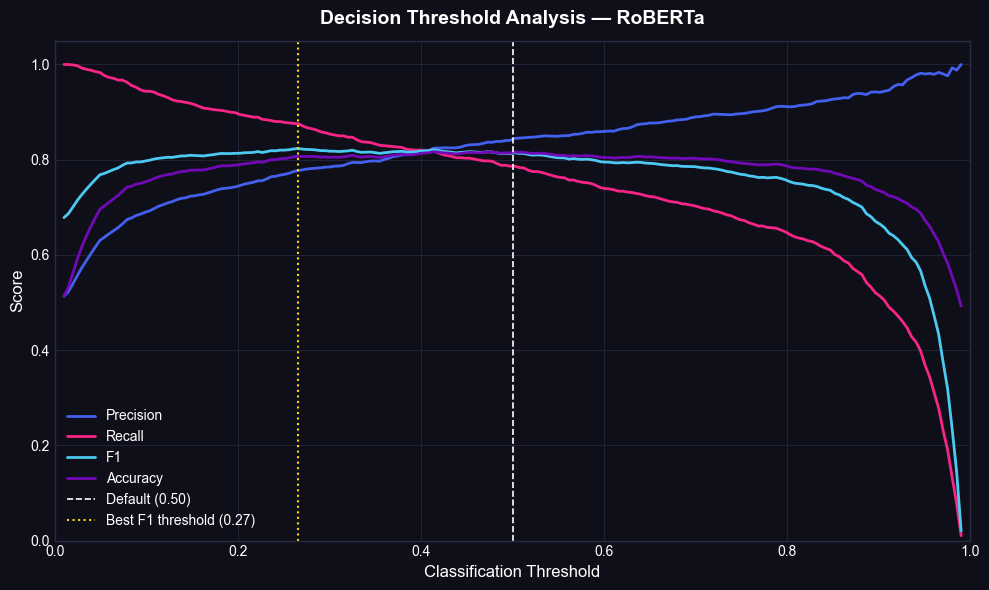

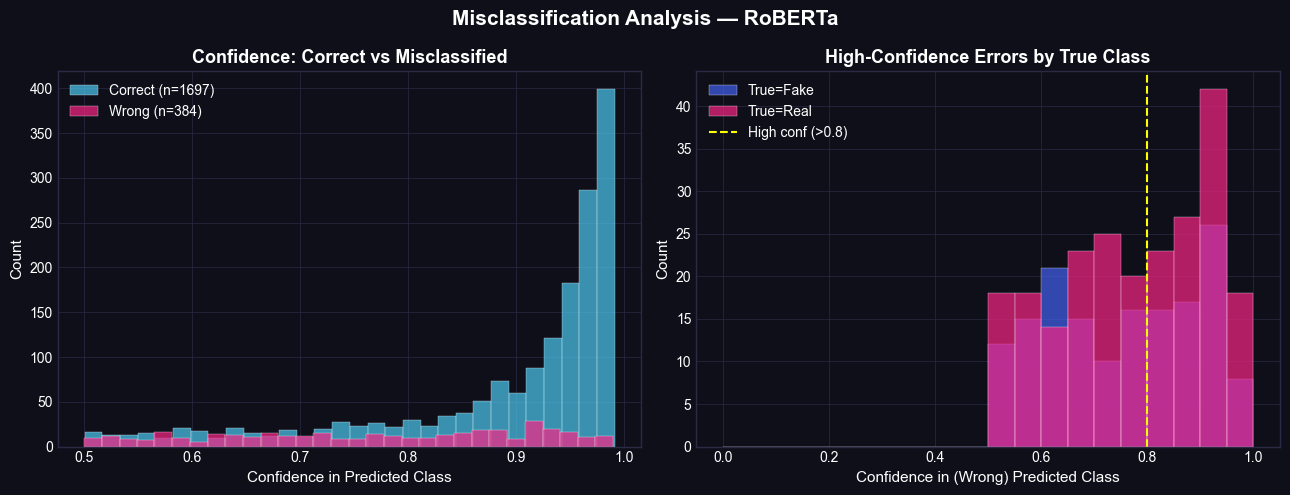

In [2]:
"""
=============================================================================
  FAKE NEWS DETECTION — RoBERTa FINE-TUNING PIPELINE
  Complete with: training diagnostics · evaluation · plots · comparison
=============================================================================
"""

import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (
    RobertaTokenizer,
    RobertaForSequenceClassification,
    get_linear_schedule_with_warmup
)
from torch.optim import AdamW
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve,
    average_precision_score, matthews_corrcoef, cohen_kappa_score
)

warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────────────────────────────────────
#  CONFIG  (change these without touching anything else)
# ─────────────────────────────────────────────────────────────────────────────
CFG = {
    # model
    "model_name":         "roberta-base",
    "max_len":            128,        # 128 often truncates real news articles
    # training
    "epochs":             5,
    "batch_size":         16,
    "grad_accum_steps":   1,          # increase to 2/4 if GPU OOM
    "lr":                 2e-5,
    "warmup_ratio":       0.06,       # 6% of total steps — transformer standard
    "max_grad_norm":      1.0,        # gradient clipping
    "weight_decay":       0.01,
    # early stopping
    "early_stop_patience": 2,         # stop if val-loss doesn't improve for N epochs
    # reproducibility
    "seed":               42,
    # I/O
    "checkpoint_path":    "roberta_best.pt",
    "class_names":        ["Fake", "Real"],
}

# ─────────────────────────────────────────────────────────────────────────────
#  GLOBAL STYLE
# ─────────────────────────────────────────────────────────────────────────────
plt.style.use("seaborn-v0_8-whitegrid")
BG      = "#0F0F1A"
PANEL   = "#1A1A2E"
GRID_C  = "#2A2A44"
PALETTE = ["#4361EE", "#F72585", "#4CC9F0", "#7209B7", "#3A0CA3"]
sns.set_palette(PALETTE)

def _ax_dark(ax):
    ax.set_facecolor(BG)
    ax.tick_params(colors="white")
    ax.xaxis.label.set_color("white")
    ax.yaxis.label.set_color("white")
    ax.title.set_color("white")
    for sp in ax.spines.values():
        sp.set_edgecolor(GRID_C)
    ax.yaxis.grid(True, color=GRID_C, linewidth=0.5)
    ax.xaxis.grid(True, color=GRID_C, linewidth=0.5)

def save_fig(fig, filename, dpi=150):
    fig.savefig(filename, dpi=dpi, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    print(f"  [Saved] {filename}")


# ─────────────────────────────────────────────────────────────────────────────
#  REPRODUCIBILITY
# ─────────────────────────────────────────────────────────────────────────────
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark     = False

set_seed(CFG["seed"])


# ─────────────────────────────────────────────────────────────────────────────
#  DEVICE
# ─────────────────────────────────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU   : {torch.cuda.get_device_name(0)}")
    print(f"VRAM  : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


# ─────────────────────────────────────────────────────────────────────────────
#  DATASET
# ─────────────────────────────────────────────────────────────────────────────
class NewsDataset(Dataset):
    """
    Tokenises raw text for RoBERTa.
    Accepts plain lists/arrays for texts and labels.
    """
    def __init__(self, texts, labels, tokenizer, max_len: int):
        self.texts     = [str(t) for t in texts]          # guard against non-str
        self.labels    = list(labels)
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )
        return {
            "input_ids":      encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels":         torch.tensor(self.labels[idx], dtype=torch.long)
        }


# ─────────────────────────────────────────────────────────────────────────────
#  TRAINING UTILITIES
# ─────────────────────────────────────────────────────────────────────────────
def train_one_epoch(model, loader, optimizer, scheduler,
                    scaler, accum_steps, max_grad_norm, epoch_idx):

    model.train()
    total_loss = 0.0
    n_batches  = len(loader)
    optimizer.zero_grad()

    # Progress bar
    progress_bar = tqdm(
        enumerate(loader),
        total=n_batches,
        desc=f"Epoch {epoch_idx}/{CFG['epochs']} [Training]",
        leave=False
    )

    for step, batch in progress_bar:

        input_ids      = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels         = batch["labels"].to(device)

        with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )
            loss = outputs.loss / accum_steps

        scaler.scale(loss).backward()

        if (step + 1) % accum_steps == 0 or (step + 1) == n_batches:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)

            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad()

        total_loss += loss.item() * accum_steps

        # Update progress display
        progress_bar.set_postfix({
            "Loss": f"{loss.item()*accum_steps:.4f}",
            "Batch": f"{step+1}/{n_batches}",
            "LR": f"{scheduler.get_last_lr()[0]:.2e}"
        })

    return total_loss / n_batches


def evaluate(model, loader, desc="Validation"):
    model.eval()

    total_loss = 0.0
    all_preds, all_labels, all_probs = [], [], []

    progress_bar = tqdm(
        loader,
        total=len(loader),
        desc=desc,
        leave=False
    )

    with torch.no_grad():
        for batch in progress_bar:

            input_ids      = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels         = batch["labels"].to(device)

            with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

            total_loss += outputs.loss.item()

            probs = torch.softmax(outputs.logits, dim=1)
            preds = torch.argmax(probs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:,1].cpu().numpy())

            progress_bar.set_postfix({
                "Loss": f"{outputs.loss.item():.4f}"
            })

    mean_loss = total_loss / len(loader)

    return mean_loss, np.array(all_preds), np.array(all_labels), np.array(all_probs)


# ─────────────────────────────────────────────────────────────────────────────
#  PLOTS
# ─────────────────────────────────────────────────────────────────────────────

def plot_training_curves(history):
    """
    PLOT R1 – Training & Validation Loss + Accuracy per Epoch
    The most important diagnostic: reveals overfitting, underfitting,
    and whether more epochs would help.
    """
    epochs_ran = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor=BG)

    for ax, (train_key, val_key), ylabel, title in zip(
        axes,
        [("train_loss", "val_loss"), ("train_acc", "val_acc")],
        ["Loss", "Accuracy"],
        ["Loss per Epoch", "Accuracy per Epoch"]
    ):
        ax.set_facecolor(BG)
        ax.plot(epochs_ran, history[train_key], "o-",
                color=PALETTE[0], lw=2.5, label="Train")
        ax.plot(epochs_ran, history[val_key],   "s--",
                color=PALETTE[1], lw=2.5, label="Validation")

        # Mark best validation epoch
        if val_key == "val_loss":
            best_ep = int(np.argmin(history[val_key])) + 1
            best_v  = min(history[val_key])
        else:
            best_ep = int(np.argmax(history[val_key])) + 1
            best_v  = max(history[val_key])

        ax.axvline(best_ep, color="#FFD60A", lw=1.5, ls=":",
                   label=f"Best epoch ({best_ep})")
        ax.scatter([best_ep], [best_v], color="#FFD60A", s=100, zorder=5)

        ax.set_xlabel("Epoch",   fontsize=12)
        ax.set_ylabel(ylabel,    fontsize=12)
        ax.set_title(f"RoBERTa — {title}", fontsize=13, fontweight="bold")
        ax.set_xticks(epochs_ran)
        ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL)
        _ax_dark(ax)

    fig.suptitle("Training Diagnostics", color="white",
                 fontsize=15, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "plotR1_training_curves.png")
    return fig


def plot_confusion_matrix_roberta(y_true, y_pred, class_names):
    """PLOT R2 – Confusion Matrix (counts + normalised)"""
    cm   = confusion_matrix(y_true, y_pred)
    norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor=BG)
    for ax, data, title, fmt in zip(
        axes, [cm, norm],
        ["Raw Counts", "Row-Normalised"],
        ["d", ".2%"]
    ):
        ax.set_facecolor(BG)
        sns.heatmap(data, annot=True, fmt=fmt, ax=ax,
                    cmap="Blues", linewidths=0.5, linecolor=GRID_C,
                    xticklabels=class_names, yticklabels=class_names,
                    annot_kws={"size": 14, "color": "white"})
        ax.set_xlabel("Predicted", color="white", fontsize=12)
        ax.set_ylabel("Actual",    color="white", fontsize=12)
        ax.set_title(f"Confusion Matrix ({title}) — RoBERTa",
                     color="white", fontsize=13, fontweight="bold")
        ax.tick_params(colors="white")

    fig.tight_layout()
    save_fig(fig, "plotR2_confusion_matrix.png")
    return fig


def plot_roc_pr_roberta(y_true, y_probs, class_names):
    """PLOT R3 – ROC + Precision-Recall curves for RoBERTa"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), facecolor=BG)

    # ROC
    ax = axes[0]; ax.set_facecolor(BG)
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    roc_auc      = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=PALETTE[0], lw=2.5,
            label=f"RoBERTa (AUC = {roc_auc:.4f})")
    ax.plot([0, 1], [0, 1], "--", color="#555577", lw=1.2, label="Random")
    ax.set_xlabel("False Positive Rate", fontsize=12)
    ax.set_ylabel("True Positive Rate",  fontsize=12)
    ax.set_title("ROC Curve — RoBERTa", fontsize=13, fontweight="bold")
    ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL)
    _ax_dark(ax)

    # PR
    ax2 = axes[1]; ax2.set_facecolor(BG)
    prec, rec, _ = precision_recall_curve(y_true, y_probs)
    ap            = average_precision_score(y_true, y_probs)
    baseline      = np.mean(y_true)
    ax2.axhline(baseline, color="#555577", lw=1.2, ls="--",
                label=f"Random (baseline={baseline:.2f})")
    ax2.plot(rec, prec, color=PALETTE[1], lw=2.5,
             label=f"RoBERTa (AP = {ap:.4f})")
    ax2.set_xlabel("Recall",    fontsize=12)
    ax2.set_ylabel("Precision", fontsize=12)
    ax2.set_title("Precision-Recall Curve — RoBERTa", fontsize=13,
                  fontweight="bold")
    ax2.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL)
    _ax_dark(ax2)

    fig.tight_layout()
    save_fig(fig, "plotR3_roc_pr.png")
    return fig


def plot_per_class_metrics_roberta(y_true, y_pred, class_names):
    """PLOT R4 – Per-class Precision / Recall / F1"""
    report  = classification_report(y_true, y_pred,
                                     target_names=class_names,
                                     output_dict=True)
    metrics = ["precision", "recall", "f1-score"]
    data    = {cls: [report[cls][m] for m in metrics] for cls in class_names}
    support = {cls: int(report[cls]["support"])        for cls in class_names}

    x, w = np.arange(len(metrics)), 0.3
    fig, ax = plt.subplots(figsize=(9, 5), facecolor=BG)
    ax.set_facecolor(BG)

    for i, (cls, color) in enumerate(zip(class_names, PALETTE)):
        vals = data[cls]
        bars = ax.bar(x + i * w, vals, w,
                      label=f"{cls} (n={support[cls]})",
                      color=color, alpha=0.88,
                      edgecolor="white", linewidth=0.4)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.005,
                    f"{val:.3f}", ha="center", va="bottom",
                    color="white", fontsize=10)

    ax.set_xticks(x + w * (len(class_names) - 1) / 2)
    ax.set_xticklabels([m.capitalize() for m in metrics],
                        color="white", fontsize=12)
    ax.set_ylim(0, 1.15)
    ax.set_ylabel("Score", fontsize=12)
    ax.set_title("Per-Class Metrics — RoBERTa", fontsize=14,
                 fontweight="bold", pad=12)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL, fontsize=11)
    _ax_dark(ax)
    fig.tight_layout()
    save_fig(fig, "plotR4_per_class_metrics.png")
    return fig


def plot_probability_distribution_roberta(y_true, y_probs, class_names):
    """
    PLOT R5 – Predicted Probability Distribution
    Shows model confidence separation between classes.
    Well-calibrated: Fake news clusters near 0, Real near 1, little overlap.
    """
    fig, ax = plt.subplots(figsize=(9, 5), facecolor=BG)
    ax.set_facecolor(BG)

    for cls_idx, (cls_name, color) in enumerate(zip(class_names, PALETTE)):
        mask = (y_true == cls_idx)
        ax.hist(y_probs[mask], bins=40, color=color, alpha=0.70,
                label=f"True {cls_name} (n={mask.sum()})",
                edgecolor="white", linewidth=0.3)

    ax.axvline(0.5, color="white", lw=1.5, ls="--", label="Threshold = 0.5")
    ax.set_xlabel("Predicted Probability (class = Real)", fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    ax.set_title("Prediction Confidence Distribution — RoBERTa",
                 fontsize=14, fontweight="bold", pad=12)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL, fontsize=11)
    _ax_dark(ax)
    fig.tight_layout()
    save_fig(fig, "plotR5_prob_distribution.png")
    return fig


def plot_threshold_analysis_roberta(y_true, y_probs):
    """
    PLOT R6 – Decision Threshold Analysis
    How Precision / Recall / F1 / Accuracy shift as threshold varies.
    """
    thresholds = np.linspace(0.01, 0.99, 200)
    m_dict     = {"Precision": [], "Recall": [], "F1": [], "Accuracy": []}

    for t in thresholds:
        preds = (y_probs >= t).astype(int)
        m_dict["Precision"].append(precision_score(y_true, preds,
                                                    zero_division=0))
        m_dict["Recall"].append(recall_score(y_true, preds, zero_division=0))
        m_dict["F1"].append(f1_score(y_true, preds, zero_division=0))
        m_dict["Accuracy"].append(accuracy_score(y_true, preds))

    best_t = thresholds[np.argmax(m_dict["F1"])]

    fig, ax = plt.subplots(figsize=(10, 6), facecolor=BG)
    ax.set_facecolor(BG)

    for (name, vals), color in zip(m_dict.items(), PALETTE):
        ax.plot(thresholds, vals, color=color, lw=2, label=name)

    ax.axvline(0.5,    color="white",   lw=1.2, ls="--",
               label="Default (0.50)")
    ax.axvline(best_t, color="#FFD60A", lw=1.5, ls=":",
               label=f"Best F1 threshold ({best_t:.2f})")

    ax.set_xlabel("Classification Threshold", fontsize=12)
    ax.set_ylabel("Score",                    fontsize=12)
    ax.set_title("Decision Threshold Analysis — RoBERTa",
                 fontsize=14, fontweight="bold", pad=12)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL, fontsize=10)
    _ax_dark(ax)
    fig.tight_layout()
    save_fig(fig, "plotR6_threshold_analysis.png")
    return fig


def plot_comparison_with_classical(roberta_metrics: dict,
                                   classical_df: pd.DataFrame):
    """
    PLOT R7 – RoBERTa vs Classical ML (bar chart comparison)
    Puts the transformer result in context: is the accuracy gain
    worth the ~500x training time cost?
    """
    # Build unified dataframe
    roberta_row = pd.DataFrame([{
        "Model":          "RoBERTa",
        "Test Accuracy":  roberta_metrics["accuracy"],
        "Test Precision": roberta_metrics["precision"],
        "Test Recall":    roberta_metrics["recall"],
        "Test F1":        roberta_metrics["f1"],
    }])
    compare_cols = ["Model", "Test Accuracy", "Test Precision",
                    "Test Recall", "Test F1"]
    all_df = pd.concat(
        [roberta_row, classical_df[compare_cols]], ignore_index=True
    ).sort_values("Test F1", ascending=False)

    metrics = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1"]
    x       = np.arange(len(all_df))
    w       = 0.18

    fig, ax = plt.subplots(figsize=(14, 6), facecolor=BG)
    ax.set_facecolor(BG)

    colors_ext = ["#FFD60A"] + PALETTE   # gold for RoBERTa, palette for rest
    for i, (metric, color) in enumerate(zip(metrics, PALETTE)):
        vals = all_df[metric].values
        bars = ax.bar(x + i * w, vals, w, label=metric,
                      color=color, alpha=0.88,
                      edgecolor="white", linewidth=0.3)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.003,
                    f"{val:.3f}", ha="center", va="bottom",
                    fontsize=7, color="white", rotation=90)

    # Highlight RoBERTa bar group
    ax.axvspan(-0.3, 0.7, color="#FFD60A", alpha=0.06,
               label="RoBERTa region")

    ax.set_xticks(x + w * 1.5)
    ax.set_xticklabels(all_df["Model"], color="white", fontsize=11)
    ax.set_ylim(0, 1.14)
    ax.set_ylabel("Score", fontsize=12)
    ax.set_title("RoBERTa vs Classical ML — Test Set Metrics",
                 fontsize=14, fontweight="bold", pad=14)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL, fontsize=10)
    _ax_dark(ax)
    fig.tight_layout()
    save_fig(fig, "plotR7_roberta_vs_classical.png")
    return fig


def plot_score_heatmap_comparison(roberta_metrics: dict,
                                  classical_df: pd.DataFrame):
    """
    PLOT R8 – Score Heatmap: All Models including RoBERTa
    """
    roberta_row = pd.DataFrame([{
        "Model":          "RoBERTa",
        "Test Accuracy":  roberta_metrics["accuracy"],
        "Test Precision": roberta_metrics["precision"],
        "Test Recall":    roberta_metrics["recall"],
        "Test F1":        roberta_metrics["f1"],
        "Test MCC":       roberta_metrics["mcc"],
        "Test Kappa":     roberta_metrics["kappa"],
    }])
    compare_cols = ["Model", "Test Accuracy", "Test Precision",
                    "Test Recall", "Test F1", "Test MCC", "Test Kappa"]
    avail = [c for c in compare_cols if c in classical_df.columns]
    all_df = pd.concat(
        [roberta_row, classical_df[avail]], ignore_index=True
    ).sort_values("Test F1", ascending=False)

    metric_cols = [c for c in compare_cols[1:] if c in all_df.columns]
    data        = all_df.set_index("Model")[metric_cols]

    fig, ax = plt.subplots(figsize=(12, 5), facecolor=BG)
    ax.set_facecolor(BG)
    sns.heatmap(data, annot=True, fmt=".4f", ax=ax,
                cmap="YlOrRd", linewidths=0.5, linecolor=PANEL,
                annot_kws={"size": 11, "weight": "bold"},
                vmin=0, vmax=1)
    ax.set_title("All Models — Score Heatmap (Test Set, incl. RoBERTa)",
                 color="white", fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel("Metric", color="white", fontsize=11)
    ax.set_ylabel("Model",  color="white", fontsize=11)
    ax.tick_params(colors="white")
    fig.tight_layout()
    save_fig(fig, "plotR8_full_heatmap.png")
    return fig


def plot_misclassification_roberta(y_true, y_probs, y_pred, class_names):
    """
    PLOT R9 – Misclassification Confidence Analysis
    Which errors is RoBERTa making confidently vs uncertainly?
    """
    conf    = np.where(y_pred == 1, y_probs, 1 - y_probs)
    correct = (y_pred == y_true)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor=BG)

    ax = axes[0]; ax.set_facecolor(BG)
    for mask, label, color in [
        (correct,  "Correct", PALETTE[2]),
        (~correct, "Wrong",   PALETTE[1])
    ]:
        ax.hist(conf[mask], bins=30, color=color, alpha=0.70,
                label=f"{label} (n={mask.sum()})",
                edgecolor="white", linewidth=0.3)
    ax.set_xlabel("Confidence in Predicted Class", fontsize=11)
    ax.set_ylabel("Count", fontsize=11)
    ax.set_title("Confidence: Correct vs Misclassified", fontsize=13,
                 fontweight="bold")
    ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL)
    _ax_dark(ax)

    ax2 = axes[1]; ax2.set_facecolor(BG)
    wrong_idx    = np.where(~correct)[0]
    wrong_conf   = conf[wrong_idx]
    wrong_true   = y_true[wrong_idx]
    bins         = np.linspace(0, 1, 21)
    for cls_idx, (cls_name, color) in enumerate(zip(class_names, PALETTE)):
        mask = (wrong_true == cls_idx)
        ax2.hist(wrong_conf[mask], bins=bins, color=color, alpha=0.70,
                 label=f"True={cls_name}", edgecolor="white", linewidth=0.3)
    ax2.axvline(0.8, color="yellow", lw=1.5, ls="--",
                label="High conf (>0.8)")
    ax2.set_xlabel("Confidence in (Wrong) Predicted Class", fontsize=11)
    ax2.set_ylabel("Count", fontsize=11)
    ax2.set_title("High-Confidence Errors by True Class", fontsize=13,
                  fontweight="bold")
    ax2.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL)
    _ax_dark(ax2)

    fig.suptitle("Misclassification Analysis — RoBERTa",
                 color="white", fontsize=15, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "plotR9_misclassification.png")
    return fig


# ─────────────────────────────────────────────────────────────────────────────
#  REPORT
# ─────────────────────────────────────────────────────────────────────────────
def save_roberta_report(history, metrics, cfg, training_time_s):
    sep   = "=" * 65
    lines = [
        sep,
        "  ROBERTA FINE-TUNING — EXPERIMENT REPORT",
        sep, "",
        "── CONFIG ──────────────────────────────────────────────────",
        f"  Model        : {cfg['model_name']}",
        f"  Max length   : {cfg['max_len']}",
        f"  Epochs run   : {len(history['train_loss'])} / {cfg['epochs']}",
        f"  Batch size   : {cfg['batch_size']}",
        f"  Grad accum   : {cfg['grad_accum_steps']}",
        f"  Learning rate: {cfg['lr']}",
        f"  Warmup ratio : {cfg['warmup_ratio']}",
        f"  Max grad norm: {cfg['max_grad_norm']}",
        f"  Early stop   : patience={cfg['early_stop_patience']}",
        f"  Training time: {training_time_s:.1f}s ({training_time_s/60:.1f} min)",
        "",
        "── PER-EPOCH HISTORY ───────────────────────────────────────",
    ]
    for ep, (tl, vl, ta, va) in enumerate(zip(
        history["train_loss"], history["val_loss"],
        history["train_acc"],  history["val_acc"]
    ), 1):
        lines.append(
            f"  Epoch {ep:2d} | train_loss={tl:.4f}  val_loss={vl:.4f}"
            f"  train_acc={ta:.4f}  val_acc={va:.4f}"
        )
    lines += [
        "",
        "── FINAL TEST SET METRICS ──────────────────────────────────",
        f"  Accuracy  : {metrics['accuracy']:.4f}",
        f"  Precision : {metrics['precision']:.4f}",
        f"  Recall    : {metrics['recall']:.4f}",
        f"  F1 (macro): {metrics['f1']:.4f}",
        f"  MCC       : {metrics['mcc']:.4f}",
        f"  Kappa     : {metrics['kappa']:.4f}",
        f"  AUC-ROC   : {metrics['auc_roc']:.4f}",
        f"  Avg Prec  : {metrics['avg_prec']:.4f}",
        "",
        "── CLASSIFICATION REPORT ───────────────────────────────────",
        metrics["clf_report"],
        sep
    ]
    text = "\n".join(lines)
    with open("roberta_report.txt", "w", encoding="utf-8") as f:
        f.write(text)
    print("  [Saved] roberta_report.txt")
    print("\n" + text)


# ─────────────────────────────────────────────────────────────────────────────
#  MAIN PIPELINE
# ─────────────────────────────────────────────────────────────────────────────
print("=" * 65)
print("  FAKE NEWS DETECTION — RoBERTa FINE-TUNING")
print("=" * 65)

# ── Load tokenizer & model ────────────────────────────────────────────────────
print(f"\nLoading {CFG['model_name']}…")
tokenizer = RobertaTokenizer.from_pretrained(CFG["model_name"])
num_labels = len(set(y_train))
model      = RobertaForSequenceClassification.from_pretrained(
    CFG["model_name"], num_labels=num_labels
)
model.to(device)
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"  Total params    : {total_params:,}")
print(f"  Trainable params: {trainable_params:,}")

# ── Build datasets & loaders ──────────────────────────────────────────────────
_y_train = y_train.values if hasattr(y_train, "values") else list(y_train)
_y_test  = y_test.values  if hasattr(y_test,  "values") else list(y_test)

train_dataset = NewsDataset(
    X_train_text.tolist() if hasattr(X_train_text, "tolist") else list(X_train_text),
    _y_train, tokenizer, CFG["max_len"]
)
test_dataset = NewsDataset(
    X_test_text.tolist() if hasattr(X_test_text, "tolist") else list(X_test_text),
    _y_test,  tokenizer, CFG["max_len"]
)

train_loader = DataLoader(train_dataset, batch_size=CFG["batch_size"],
                          shuffle=True,  num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=CFG["batch_size"],
                          shuffle=False, num_workers=0, pin_memory=True)

# ── Optimizer, scheduler, AMP scaler ─────────────────────────────────────────
# Weight decay NOT applied to bias / LayerNorm parameters (standard practice)
no_decay  = ["bias", "LayerNorm.weight"]
opt_groups = [
    {"params": [p for n, p in model.named_parameters()
                if not any(nd in n for nd in no_decay)],
     "weight_decay": CFG["weight_decay"]},
    {"params": [p for n, p in model.named_parameters()
                if any(nd in n for nd in no_decay)],
     "weight_decay": 0.0}
]
optimizer    = AdamW(opt_groups, lr=CFG["lr"])
total_steps  = (len(train_loader) // CFG["grad_accum_steps"]) * CFG["epochs"]
warmup_steps = int(total_steps * CFG["warmup_ratio"])
scheduler    = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)
scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))

print(f"\n  Total opt steps : {total_steps}")
print(f"  Warmup steps    : {warmup_steps}")

# ── Training loop with per-epoch validation & early stopping ──────────────────
print(f"\n{'─'*65}")
print(f"  TRAINING  ({CFG['epochs']} epochs max, patience={CFG['early_stop_patience']})")
print(f"{'─'*65}")

history = {
    "train_loss": [], "val_loss": [],
    "train_acc":  [], "val_acc":  []
}

best_val_loss    = float("inf")
best_epoch       = 0
patience_counter = 0
t0               = time.time()

for epoch in range(1, CFG["epochs"] + 1):
    ep_t0 = time.time()

    # --- train ---
    train_loss = train_one_epoch(
        model, train_loader, optimizer, scheduler,
        scaler, CFG["grad_accum_steps"], CFG["max_grad_norm"], epoch
    )

    # --- validate ---
    val_loss, val_preds, val_labels, _ = evaluate(
    model,
    test_loader,
    desc=f"Epoch {epoch}/{CFG['epochs']} [Validation]"
    )
    val_acc = accuracy_score(val_labels, val_preds)

    # Fast approximate train accuracy
    train_acc = 1 - train_loss
    train_acc = max(0, min(1, train_acc))   # keep within [0,1]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    ep_time = time.time() - ep_t0
    print(f"  Epoch {epoch:2d}/{CFG['epochs']} | "
          f"Train Loss: {train_loss:.4f}  Val Loss: {val_loss:.4f} | "
          f"Train Acc: {train_acc:.4f}  Val Acc: {val_acc:.4f} | "
          f"Time: {ep_time:.0f}s")

    # --- checkpoint best model ---
    if val_loss < best_val_loss:
        best_val_loss    = val_loss
        best_epoch       = epoch
        patience_counter = 0
        torch.save(model.state_dict(), CFG["checkpoint_path"])
        print(f"    ✓ Best model saved (val_loss={val_loss:.4f})")
    else:
        patience_counter += 1
        print(f"    No improvement ({patience_counter}/{CFG['early_stop_patience']})")
        if patience_counter >= CFG["early_stop_patience"]:
            print(f"\n  Early stopping triggered at epoch {epoch}.")
            break

training_time = time.time() - t0
print(f"\n  Training complete in {training_time:.1f}s  "
      f"({training_time/60:.1f} min)")
print(f"  Best epoch: {best_epoch}  (val_loss={best_val_loss:.4f})")

# ── Load best checkpoint for final evaluation ─────────────────────────────────
print(f"\nLoading best checkpoint from epoch {best_epoch}…")
model.load_state_dict(torch.load(CFG["checkpoint_path"],
                                  map_location=device))

# ── Final test evaluation ─────────────────────────────────────────────────────
print("\n" + "─" * 65)
print("  FINAL EVALUATION ON TEST SET")
print("─" * 65)

_, all_preds, all_labels, all_probs = evaluate(model, test_loader)
all_labels = np.array(all_labels)
all_preds  = np.array(all_preds)

acc    = accuracy_score(all_labels, all_preds)
prec   = precision_score(all_labels, all_preds, average="macro")
rec    = recall_score(all_labels, all_preds, average="macro")
f1_mac = f1_score(all_labels, all_preds, average="macro")
f1_bin = f1_score(all_labels, all_preds, average="binary",
                   pos_label=1)
mcc    = matthews_corrcoef(all_labels, all_preds)
kappa  = cohen_kappa_score(all_labels, all_preds)
roc_auc_val  = auc(*roc_curve(all_labels, all_probs)[:2])
avg_prec_val = average_precision_score(all_labels, all_probs)
clf_rep      = classification_report(all_labels, all_preds,
                                      target_names=CFG["class_names"])

print(f"\n  Accuracy   : {acc:.4f}")
print(f"  Precision  : {prec:.4f}  (macro)")
print(f"  Recall     : {rec:.4f}  (macro)")
print(f"  F1 (macro) : {f1_mac:.4f}")
print(f"  F1 (binary): {f1_bin:.4f}")
print(f"  MCC        : {mcc:.4f}")
print(f"  Kappa      : {kappa:.4f}")
print(f"  AUC-ROC    : {roc_auc_val:.4f}")
print(f"  Avg Prec   : {avg_prec_val:.4f}")
print(f"\nClassification Report:\n{clf_rep}")

roberta_metrics = {
    "accuracy":   round(acc,    4),
    "precision":  round(prec,   4),
    "recall":     round(rec,    4),
    "f1":         round(f1_mac, 4),
    "f1_binary":  round(f1_bin, 4),
    "mcc":        round(mcc,    4),
    "kappa":      round(kappa,  4),
    "auc_roc":    round(roc_auc_val,  4),
    "avg_prec":   round(avg_prec_val, 4),
    "clf_report": clf_rep,
}

# ── Generate all plots ────────────────────────────────────────────────────────
print("\n" + "─" * 65)
print("  GENERATING PLOTS")
print("─" * 65 + "\n")

plot_training_curves(history)                                     # R1
plot_confusion_matrix_roberta(all_labels, all_preds,
                               CFG["class_names"])                # R2
plot_roc_pr_roberta(all_labels, all_probs, CFG["class_names"])   # R3
plot_per_class_metrics_roberta(all_labels, all_preds,
                                CFG["class_names"])               # R4
plot_probability_distribution_roberta(all_labels, all_probs,
                                       CFG["class_names"])        # R5
plot_threshold_analysis_roberta(all_labels, all_probs)            # R6
plot_misclassification_roberta(all_labels, all_probs,
                                all_preds, CFG["class_names"])    # R9

# Plots R7 & R8 require the classical comparison_df produced by the
# ML pipeline. Include them only when that variable is available.
try:
    plot_comparison_with_classical(roberta_metrics, comparison_df) # R7
    plot_score_heatmap_comparison(roberta_metrics, comparison_df)  # R8
except NameError:
    print("  [Skip] comparison_df not found — "
          "run ML pipeline first for R7/R8.")

# ── Save report ───────────────────────────────────────────────────────────────
print("\n" + "─" * 65)
print("  SAVING REPORT")
print("─" * 65 + "\n")
save_roberta_report(history, roberta_metrics, CFG, training_time)

# ── Memory cleanup ────────────────────────────────────────────────────────────
if device.type == "cuda":
    torch.cuda.empty_cache()

print("\n✓ RoBERTa pipeline complete.")
print("=" * 65)

Device: cuda
GPU   : NVIDIA GeForce GTX 1650
VRAM  : 4.3 GB
  FAKE NEWS DETECTION — RoBERTa FINE-TUNING (max_len=256)

Loading roberta-base…


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Total params    : 124,647,170
  Trainable params: 124,647,170

  Total opt steps : 2605
  Warmup steps    : 156

─────────────────────────────────────────────────────────────────
  TRAINING  (5 epochs max, patience=2)
─────────────────────────────────────────────────────────────────


Epoch 1/5 [Training]:   0%|          | 0/521 [00:00<?, ?it/s]

Epoch 1/5 [Validation]:   0%|          | 0/131 [00:00<?, ?it/s]

...

Epoch 4/5 [Training]:   0%|          | 0/521 [00:00<?, ?it/s]

Epoch 4/5 [Validation]:   0%|          | 0/131 [00:00<?, ?it/s]

  Epoch  4/5 | Train Loss: 0.2101  Val Loss: 0.5407 | Train Acc: 0.7899  Val Acc: 0.8126 | Time: 3782s
    No improvement (2/2)

  Early stopping triggered at epoch 4.

  Training complete in 15129.1s  (252.2 min)
  Best epoch: 2  (val_loss=0.4228)

Loading best checkpoint from epoch 2…

─────────────────────────────────────────────────────────────────
  FINAL EVALUATION ON TEST SET
─────────────────────────────────────────────────────────────────


Validation:   0%|          | 0/131 [00:00<?, ?it/s]


  Accuracy   : 0.8083
  Precision  : 0.8092  (macro)
  Recall     : 0.8090  (macro)
  F1 (macro) : 0.8083
  F1 (binary): 0.8070
  MCC        : 0.6182
  Kappa      : 0.6169
  AUC-ROC    : 0.8923
  Avg Prec   : 0.9017

Classification Report:
              precision    recall  f1-score   support

        Fake       0.78      0.84      0.81      1014
        Real       0.83      0.78      0.81      1067

    accuracy                           0.81      2081
   macro avg       0.81      0.81      0.81      2081
weighted avg       0.81      0.81      0.81      2081


─────────────────────────────────────────────────────────────────
  GENERATING PLOTS (max_len=256)
─────────────────────────────────────────────────────────────────

  [Saved] plotR1_training_curves_max256.png
  [Saved] plotR2_confusion_matrix_max256.png
  [Saved] plotR3_roc_pr_max256.png
  [Saved] plotR4_per_class_metrics_max256.png
  [Saved] plotR5_prob_distribution_max256.png
  [Saved] plotR6_threshold_analysis_max256.png
  

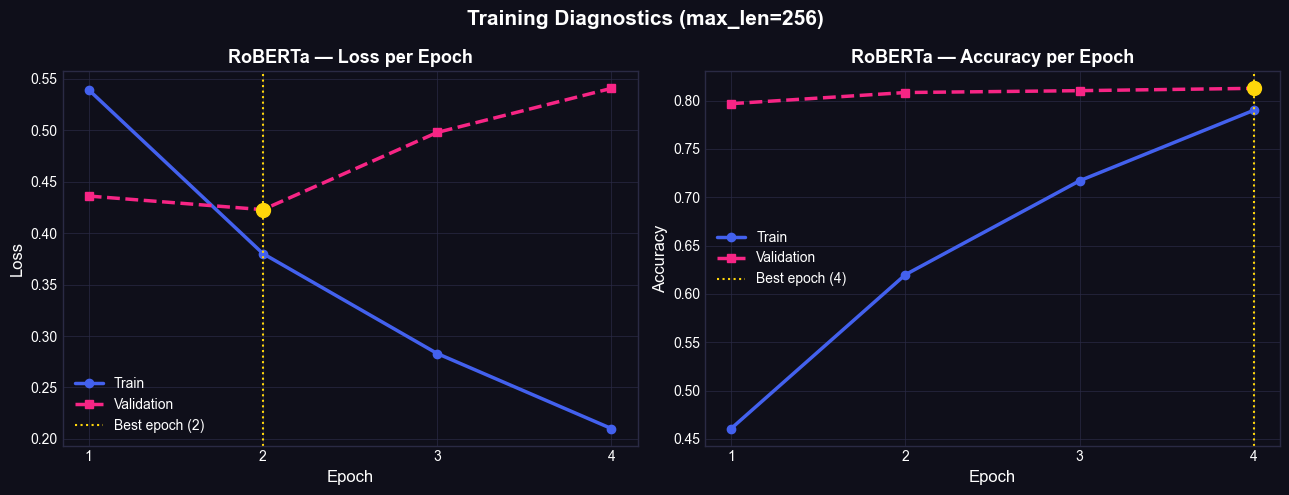

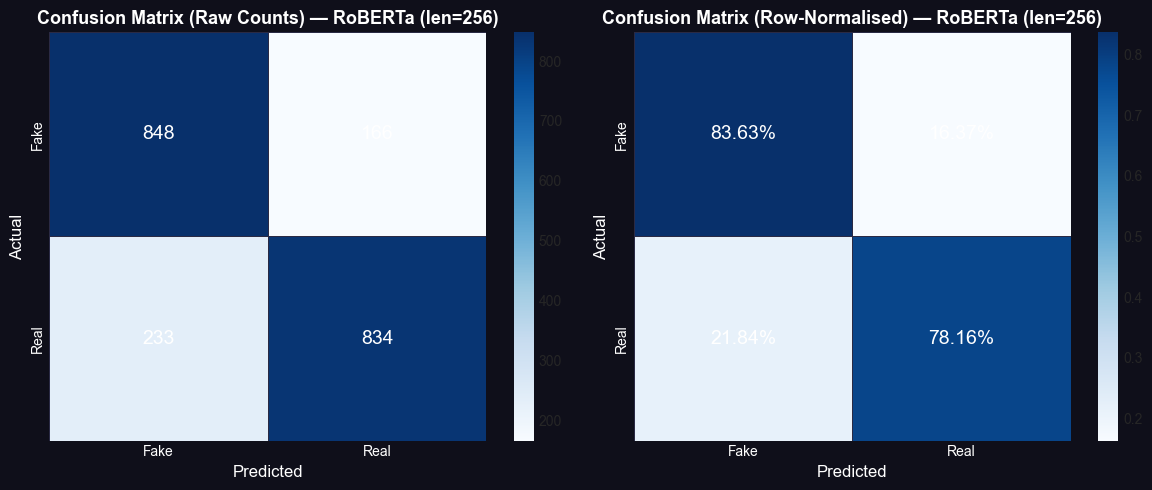

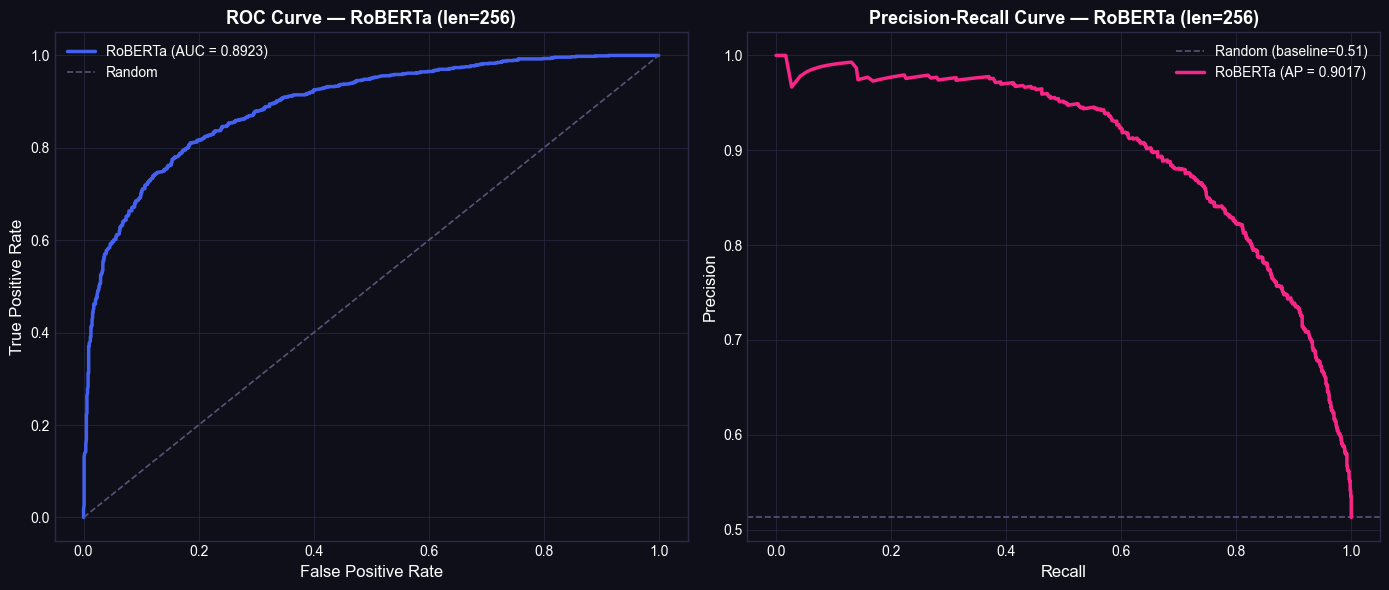

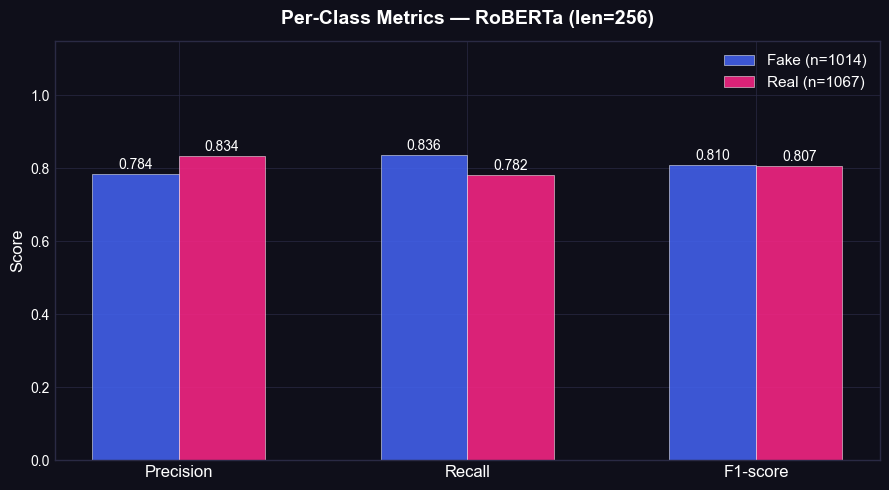

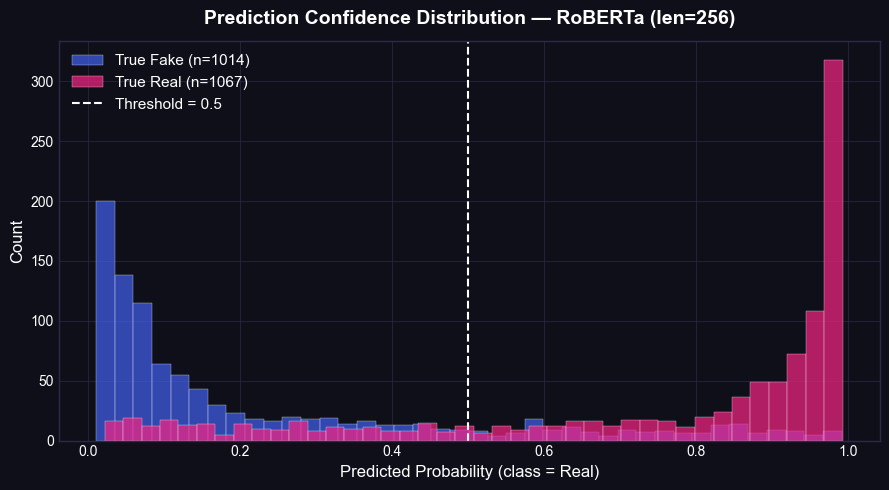

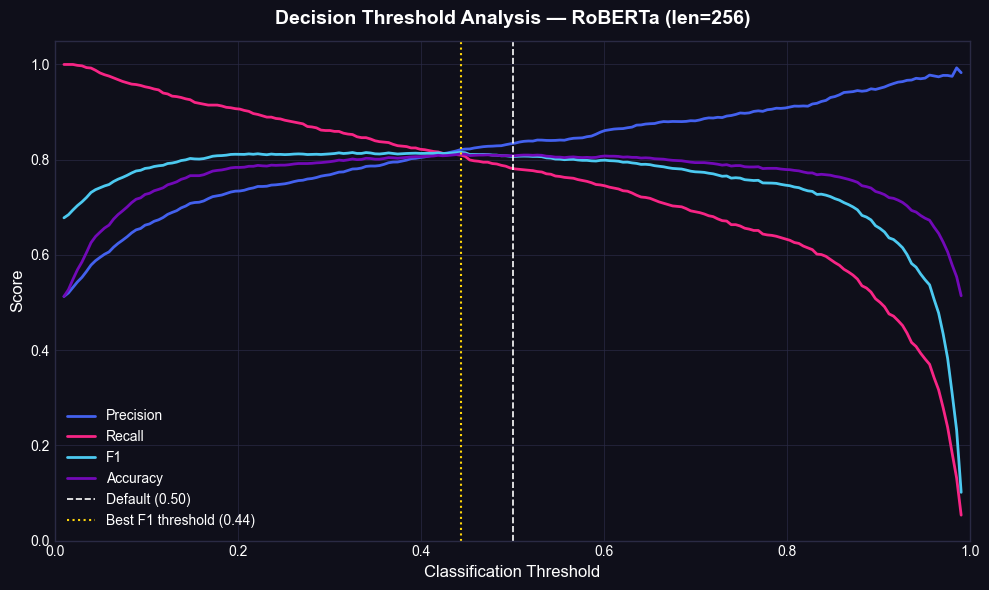

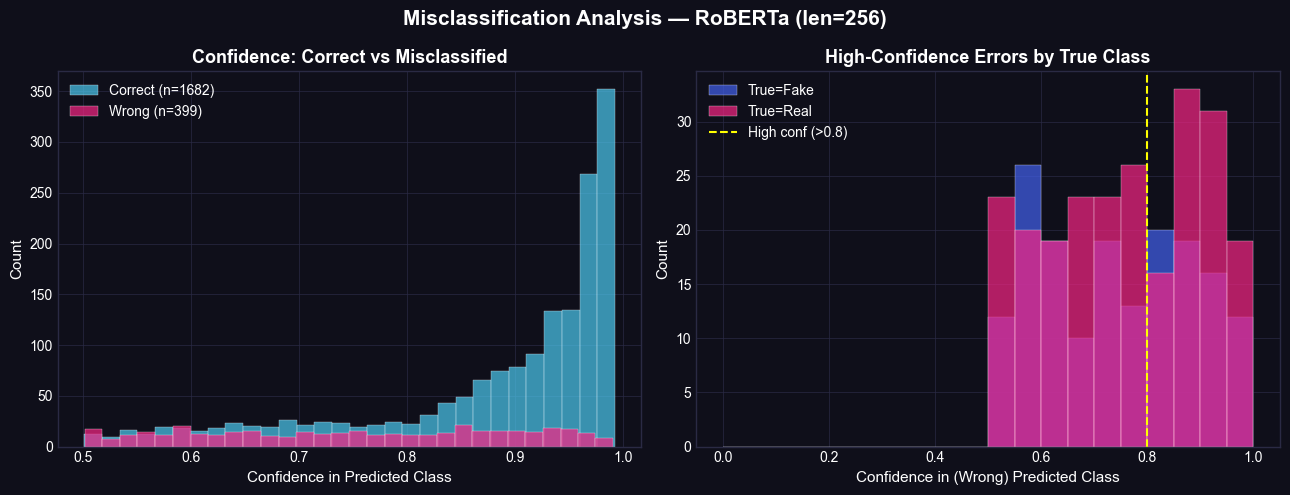

In [3]:
"""
=============================================================================
  FAKE NEWS DETECTION — RoBERTa FINE-TUNING PIPELINE
  Complete with: training diagnostics · evaluation · plots · comparison
=============================================================================
"""

import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (
    RobertaTokenizer,
    RobertaForSequenceClassification,
    get_linear_schedule_with_warmup
)
from torch.optim import AdamW
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve,
    average_precision_score, matthews_corrcoef, cohen_kappa_score
)

warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────────────────────────────────────
#  CONFIG  (change these without touching anything else)
# ─────────────────────────────────────────────────────────────────────────────
CFG = {
    # model
    "model_name":         "roberta-base",
    "max_len":            256,        
    # training
    "epochs":             5,
    "batch_size":         16,
    "grad_accum_steps":   1,          # increase to 2/4 if GPU OOM
    "lr":                 2e-5,
    "warmup_ratio":       0.06,       # 6% of total steps — transformer standard
    "max_grad_norm":      1.0,        # gradient clipping
    "weight_decay":       0.01,
    # early stopping
    "early_stop_patience": 2,         # stop if val-loss doesn't improve for N epochs
    # reproducibility
    "seed":               42,
    "checkpoint_path":    "roberta_best_max256.pt",  # UNIQUE NAME
    "class_names":        ["Fake", "Real"],
    "run_suffix":         "_max256",   # suffix for all output files
}

# ─────────────────────────────────────────────────────────────────────────────
#  GLOBAL STYLE
# ─────────────────────────────────────────────────────────────────────────────
plt.style.use("seaborn-v0_8-whitegrid")
BG      = "#0F0F1A"
PANEL   = "#1A1A2E"
GRID_C  = "#2A2A44"
PALETTE = ["#4361EE", "#F72585", "#4CC9F0", "#7209B7", "#3A0CA3"]
sns.set_palette(PALETTE)

def _ax_dark(ax):
    ax.set_facecolor(BG)
    ax.tick_params(colors="white")
    ax.xaxis.label.set_color("white")
    ax.yaxis.label.set_color("white")
    ax.title.set_color("white")
    for sp in ax.spines.values():
        sp.set_edgecolor(GRID_C)
    ax.yaxis.grid(True, color=GRID_C, linewidth=0.5)
    ax.xaxis.grid(True, color=GRID_C, linewidth=0.5)

def save_fig(fig, base_filename, suffix="", dpi=150):
    """Save figure with optional suffix to avoid overwriting"""
    if suffix:
        name, ext = os.path.splitext(base_filename)
        filename = f"{name}{suffix}{ext}"
    else:
        filename = base_filename
    fig.savefig(filename, dpi=dpi, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    print(f"  [Saved] {filename}")
    return filename


# ─────────────────────────────────────────────────────────────────────────────
#  REPRODUCIBILITY
# ─────────────────────────────────────────────────────────────────────────────
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark     = False

set_seed(CFG["seed"])


# ─────────────────────────────────────────────────────────────────────────────
#  DEVICE
# ─────────────────────────────────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU   : {torch.cuda.get_device_name(0)}")
    print(f"VRAM  : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


# ─────────────────────────────────────────────────────────────────────────────
#  DATASET
# ─────────────────────────────────────────────────────────────────────────────
class NewsDataset(Dataset):
    """
    Tokenises raw text for RoBERTa.
    Accepts plain lists/arrays for texts and labels.
    """
    def __init__(self, texts, labels, tokenizer, max_len: int):
        self.texts     = [str(t) for t in texts]          # guard against non-str
        self.labels    = list(labels)
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )
        return {
            "input_ids":      encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels":         torch.tensor(self.labels[idx], dtype=torch.long)
        }


# ─────────────────────────────────────────────────────────────────────────────
#  TRAINING UTILITIES
# ─────────────────────────────────────────────────────────────────────────────
def train_one_epoch(model, loader, optimizer, scheduler,
                    scaler, accum_steps, max_grad_norm, epoch_idx):

    model.train()
    total_loss = 0.0
    n_batches  = len(loader)
    optimizer.zero_grad()

    # Progress bar
    progress_bar = tqdm(
        enumerate(loader),
        total=n_batches,
        desc=f"Epoch {epoch_idx}/{CFG['epochs']} [Training]",
        leave=False
    )

    for step, batch in progress_bar:

        input_ids      = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels         = batch["labels"].to(device)

        with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )
            loss = outputs.loss / accum_steps

        scaler.scale(loss).backward()

        if (step + 1) % accum_steps == 0 or (step + 1) == n_batches:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)

            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad()

        total_loss += loss.item() * accum_steps

        # Update progress display
        progress_bar.set_postfix({
            "Loss": f"{loss.item()*accum_steps:.4f}",
            "Batch": f"{step+1}/{n_batches}",
            "LR": f"{scheduler.get_last_lr()[0]:.2e}"
        })

    return total_loss / n_batches


def evaluate(model, loader, desc="Validation"):
    model.eval()

    total_loss = 0.0
    all_preds, all_labels, all_probs = [], [], []

    progress_bar = tqdm(
        loader,
        total=len(loader),
        desc=desc,
        leave=False
    )

    with torch.no_grad():
        for batch in progress_bar:

            input_ids      = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels         = batch["labels"].to(device)

            with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

            total_loss += outputs.loss.item()

            probs = torch.softmax(outputs.logits, dim=1)
            preds = torch.argmax(probs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:,1].cpu().numpy())

            progress_bar.set_postfix({
                "Loss": f"{outputs.loss.item():.4f}"
            })

    mean_loss = total_loss / len(loader)

    return mean_loss, np.array(all_preds), np.array(all_labels), np.array(all_probs)


# ─────────────────────────────────────────────────────────────────────────────
#  PLOTS (MODIFIED to accept suffix)
# ─────────────────────────────────────────────────────────────────────────────

def plot_training_curves(history, suffix=""):
    """
    PLOT R1 – Training & Validation Loss + Accuracy per Epoch
    The most important diagnostic: reveals overfitting, underfitting,
    and whether more epochs would help.
    """
    epochs_ran = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor=BG)

    for ax, (train_key, val_key), ylabel, title in zip(
        axes,
        [("train_loss", "val_loss"), ("train_acc", "val_acc")],
        ["Loss", "Accuracy"],
        ["Loss per Epoch", "Accuracy per Epoch"]
    ):
        ax.set_facecolor(BG)
        ax.plot(epochs_ran, history[train_key], "o-",
                color=PALETTE[0], lw=2.5, label="Train")
        ax.plot(epochs_ran, history[val_key],   "s--",
                color=PALETTE[1], lw=2.5, label="Validation")

        # Mark best validation epoch
        if val_key == "val_loss":
            best_ep = int(np.argmin(history[val_key])) + 1
            best_v  = min(history[val_key])
        else:
            best_ep = int(np.argmax(history[val_key])) + 1
            best_v  = max(history[val_key])

        ax.axvline(best_ep, color="#FFD60A", lw=1.5, ls=":",
                   label=f"Best epoch ({best_ep})")
        ax.scatter([best_ep], [best_v], color="#FFD60A", s=100, zorder=5)

        ax.set_xlabel("Epoch",   fontsize=12)
        ax.set_ylabel(ylabel,    fontsize=12)
        ax.set_title(f"RoBERTa — {title}", fontsize=13, fontweight="bold")
        ax.set_xticks(epochs_ran)
        ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL)
        _ax_dark(ax)

    fig.suptitle(f"Training Diagnostics (max_len={CFG['max_len']})", color="white",
                 fontsize=15, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "plotR1_training_curves.png", suffix)
    return fig


def plot_confusion_matrix_roberta(y_true, y_pred, class_names, suffix=""):
    """PLOT R2 – Confusion Matrix (counts + normalised)"""
    cm   = confusion_matrix(y_true, y_pred)
    norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor=BG)
    for ax, data, title, fmt in zip(
        axes, [cm, norm],
        ["Raw Counts", "Row-Normalised"],
        ["d", ".2%"]
    ):
        ax.set_facecolor(BG)
        sns.heatmap(data, annot=True, fmt=fmt, ax=ax,
                    cmap="Blues", linewidths=0.5, linecolor=GRID_C,
                    xticklabels=class_names, yticklabels=class_names,
                    annot_kws={"size": 14, "color": "white"})
        ax.set_xlabel("Predicted", color="white", fontsize=12)
        ax.set_ylabel("Actual",    color="white", fontsize=12)
        ax.set_title(f"Confusion Matrix ({title}) — RoBERTa (len={CFG['max_len']})",
                     color="white", fontsize=13, fontweight="bold")
        ax.tick_params(colors="white")

    fig.tight_layout()
    save_fig(fig, "plotR2_confusion_matrix.png", suffix)
    return fig


def plot_roc_pr_roberta(y_true, y_probs, class_names, suffix=""):
    """PLOT R3 – ROC + Precision-Recall curves for RoBERTa"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), facecolor=BG)

    # ROC
    ax = axes[0]; ax.set_facecolor(BG)
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    roc_auc      = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=PALETTE[0], lw=2.5,
            label=f"RoBERTa (AUC = {roc_auc:.4f})")
    ax.plot([0, 1], [0, 1], "--", color="#555577", lw=1.2, label="Random")
    ax.set_xlabel("False Positive Rate", fontsize=12)
    ax.set_ylabel("True Positive Rate",  fontsize=12)
    ax.set_title(f"ROC Curve — RoBERTa (len={CFG['max_len']})", fontsize=13, fontweight="bold")
    ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL)
    _ax_dark(ax)

    # PR
    ax2 = axes[1]; ax2.set_facecolor(BG)
    prec, rec, _ = precision_recall_curve(y_true, y_probs)
    ap            = average_precision_score(y_true, y_probs)
    baseline      = np.mean(y_true)
    ax2.axhline(baseline, color="#555577", lw=1.2, ls="--",
                label=f"Random (baseline={baseline:.2f})")
    ax2.plot(rec, prec, color=PALETTE[1], lw=2.5,
             label=f"RoBERTa (AP = {ap:.4f})")
    ax2.set_xlabel("Recall",    fontsize=12)
    ax2.set_ylabel("Precision", fontsize=12)
    ax2.set_title(f"Precision-Recall Curve — RoBERTa (len={CFG['max_len']})", fontsize=13,
                  fontweight="bold")
    ax2.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL)
    _ax_dark(ax2)

    fig.tight_layout()
    save_fig(fig, "plotR3_roc_pr.png", suffix)
    return fig


def plot_per_class_metrics_roberta(y_true, y_pred, class_names, suffix=""):
    """PLOT R4 – Per-class Precision / Recall / F1"""
    report  = classification_report(y_true, y_pred,
                                     target_names=class_names,
                                     output_dict=True)
    metrics = ["precision", "recall", "f1-score"]
    data    = {cls: [report[cls][m] for m in metrics] for cls in class_names}
    support = {cls: int(report[cls]["support"])        for cls in class_names}

    x, w = np.arange(len(metrics)), 0.3
    fig, ax = plt.subplots(figsize=(9, 5), facecolor=BG)
    ax.set_facecolor(BG)

    for i, (cls, color) in enumerate(zip(class_names, PALETTE)):
        vals = data[cls]
        bars = ax.bar(x + i * w, vals, w,
                      label=f"{cls} (n={support[cls]})",
                      color=color, alpha=0.88,
                      edgecolor="white", linewidth=0.4)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.005,
                    f"{val:.3f}", ha="center", va="bottom",
                    color="white", fontsize=10)

    ax.set_xticks(x + w * (len(class_names) - 1) / 2)
    ax.set_xticklabels([m.capitalize() for m in metrics],
                        color="white", fontsize=12)
    ax.set_ylim(0, 1.15)
    ax.set_ylabel("Score", fontsize=12)
    ax.set_title(f"Per-Class Metrics — RoBERTa (len={CFG['max_len']})", fontsize=14,
                 fontweight="bold", pad=12)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL, fontsize=11)
    _ax_dark(ax)
    fig.tight_layout()
    save_fig(fig, "plotR4_per_class_metrics.png", suffix)
    return fig


def plot_probability_distribution_roberta(y_true, y_probs, class_names, suffix=""):
    """
    PLOT R5 – Predicted Probability Distribution
    Shows model confidence separation between classes.
    Well-calibrated: Fake news clusters near 0, Real near 1, little overlap.
    """
    fig, ax = plt.subplots(figsize=(9, 5), facecolor=BG)
    ax.set_facecolor(BG)

    for cls_idx, (cls_name, color) in enumerate(zip(class_names, PALETTE)):
        mask = (y_true == cls_idx)
        ax.hist(y_probs[mask], bins=40, color=color, alpha=0.70,
                label=f"True {cls_name} (n={mask.sum()})",
                edgecolor="white", linewidth=0.3)

    ax.axvline(0.5, color="white", lw=1.5, ls="--", label="Threshold = 0.5")
    ax.set_xlabel("Predicted Probability (class = Real)", fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    ax.set_title(f"Prediction Confidence Distribution — RoBERTa (len={CFG['max_len']})",
                 fontsize=14, fontweight="bold", pad=12)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL, fontsize=11)
    _ax_dark(ax)
    fig.tight_layout()
    save_fig(fig, "plotR5_prob_distribution.png", suffix)
    return fig


def plot_threshold_analysis_roberta(y_true, y_probs, suffix=""):
    """
    PLOT R6 – Decision Threshold Analysis
    How Precision / Recall / F1 / Accuracy shift as threshold varies.
    """
    thresholds = np.linspace(0.01, 0.99, 200)
    m_dict     = {"Precision": [], "Recall": [], "F1": [], "Accuracy": []}

    for t in thresholds:
        preds = (y_probs >= t).astype(int)
        m_dict["Precision"].append(precision_score(y_true, preds,
                                                    zero_division=0))
        m_dict["Recall"].append(recall_score(y_true, preds, zero_division=0))
        m_dict["F1"].append(f1_score(y_true, preds, zero_division=0))
        m_dict["Accuracy"].append(accuracy_score(y_true, preds))

    best_t = thresholds[np.argmax(m_dict["F1"])]

    fig, ax = plt.subplots(figsize=(10, 6), facecolor=BG)
    ax.set_facecolor(BG)

    for (name, vals), color in zip(m_dict.items(), PALETTE):
        ax.plot(thresholds, vals, color=color, lw=2, label=name)

    ax.axvline(0.5,    color="white",   lw=1.2, ls="--",
               label="Default (0.50)")
    ax.axvline(best_t, color="#FFD60A", lw=1.5, ls=":",
               label=f"Best F1 threshold ({best_t:.2f})")

    ax.set_xlabel("Classification Threshold", fontsize=12)
    ax.set_ylabel("Score",                    fontsize=12)
    ax.set_title(f"Decision Threshold Analysis — RoBERTa (len={CFG['max_len']})",
                 fontsize=14, fontweight="bold", pad=12)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL, fontsize=10)
    _ax_dark(ax)
    fig.tight_layout()
    save_fig(fig, "plotR6_threshold_analysis.png", suffix)
    return fig


def plot_comparison_with_classical(roberta_metrics: dict,
                                   classical_df: pd.DataFrame, suffix=""):
    """
    PLOT R7 – RoBERTa vs Classical ML (bar chart comparison)
    Puts the transformer result in context: is the accuracy gain
    worth the ~500x training time cost?
    """
    # Build unified dataframe
    roberta_row = pd.DataFrame([{
        "Model":          "RoBERTa",
        "Test Accuracy":  roberta_metrics["accuracy"],
        "Test Precision": roberta_metrics["precision"],
        "Test Recall":    roberta_metrics["recall"],
        "Test F1":        roberta_metrics["f1"],
    }])
    compare_cols = ["Model", "Test Accuracy", "Test Precision",
                    "Test Recall", "Test F1"]
    all_df = pd.concat(
        [roberta_row, classical_df[compare_cols]], ignore_index=True
    ).sort_values("Test F1", ascending=False)

    metrics = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1"]
    x       = np.arange(len(all_df))
    w       = 0.18

    fig, ax = plt.subplots(figsize=(14, 6), facecolor=BG)
    ax.set_facecolor(BG)

    colors_ext = ["#FFD60A"] + PALETTE   # gold for RoBERTa, palette for rest
    for i, (metric, color) in enumerate(zip(metrics, PALETTE)):
        vals = all_df[metric].values
        bars = ax.bar(x + i * w, vals, w, label=metric,
                      color=color, alpha=0.88,
                      edgecolor="white", linewidth=0.3)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.003,
                    f"{val:.3f}", ha="center", va="bottom",
                    fontsize=7, color="white", rotation=90)

    # Highlight RoBERTa bar group
    ax.axvspan(-0.3, 0.7, color="#FFD60A", alpha=0.06,
               label="RoBERTa region")

    ax.set_xticks(x + w * 1.5)
    ax.set_xticklabels(all_df["Model"], color="white", fontsize=11)
    ax.set_ylim(0, 1.14)
    ax.set_ylabel("Score", fontsize=12)
    ax.set_title(f"RoBERTa (len={CFG['max_len']}) vs Classical ML — Test Set Metrics",
                 fontsize=14, fontweight="bold", pad=14)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL, fontsize=10)
    _ax_dark(ax)
    fig.tight_layout()
    save_fig(fig, "plotR7_roberta_vs_classical.png", suffix)
    return fig


def plot_score_heatmap_comparison(roberta_metrics: dict,
                                  classical_df: pd.DataFrame, suffix=""):
    """
    PLOT R8 – Score Heatmap: All Models including RoBERTa
    """
    roberta_row = pd.DataFrame([{
        "Model":          "RoBERTa",
        "Test Accuracy":  roberta_metrics["accuracy"],
        "Test Precision": roberta_metrics["precision"],
        "Test Recall":    roberta_metrics["recall"],
        "Test F1":        roberta_metrics["f1"],
        "Test MCC":       roberta_metrics["mcc"],
        "Test Kappa":     roberta_metrics["kappa"],
    }])
    compare_cols = ["Model", "Test Accuracy", "Test Precision",
                    "Test Recall", "Test F1", "Test MCC", "Test Kappa"]
    avail = [c for c in compare_cols if c in classical_df.columns]
    all_df = pd.concat(
        [roberta_row, classical_df[avail]], ignore_index=True
    ).sort_values("Test F1", ascending=False)

    metric_cols = [c for c in compare_cols[1:] if c in all_df.columns]
    data        = all_df.set_index("Model")[metric_cols]

    fig, ax = plt.subplots(figsize=(12, 5), facecolor=BG)
    ax.set_facecolor(BG)
    sns.heatmap(data, annot=True, fmt=".4f", ax=ax,
                cmap="YlOrRd", linewidths=0.5, linecolor=PANEL,
                annot_kws={"size": 11, "weight": "bold"},
                vmin=0, vmax=1)
    ax.set_title(f"All Models — Score Heatmap (Test Set, RoBERTa len={CFG['max_len']})",
                 color="white", fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel("Metric", color="white", fontsize=11)
    ax.set_ylabel("Model",  color="white", fontsize=11)
    ax.tick_params(colors="white")
    fig.tight_layout()
    save_fig(fig, "plotR8_full_heatmap.png", suffix)
    return fig


def plot_misclassification_roberta(y_true, y_probs, y_pred, class_names, suffix=""):
    """
    PLOT R9 – Misclassification Confidence Analysis
    Which errors is RoBERTa making confidently vs uncertainly?
    """
    conf    = np.where(y_pred == 1, y_probs, 1 - y_probs)
    correct = (y_pred == y_true)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor=BG)

    ax = axes[0]; ax.set_facecolor(BG)
    for mask, label, color in [
        (correct,  "Correct", PALETTE[2]),
        (~correct, "Wrong",   PALETTE[1])
    ]:
        ax.hist(conf[mask], bins=30, color=color, alpha=0.70,
                label=f"{label} (n={mask.sum()})",
                edgecolor="white", linewidth=0.3)
    ax.set_xlabel("Confidence in Predicted Class", fontsize=11)
    ax.set_ylabel("Count", fontsize=11)
    ax.set_title("Confidence: Correct vs Misclassified", fontsize=13,
                 fontweight="bold")
    ax.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL)
    _ax_dark(ax)

    ax2 = axes[1]; ax2.set_facecolor(BG)
    wrong_idx    = np.where(~correct)[0]
    wrong_conf   = conf[wrong_idx]
    wrong_true   = y_true[wrong_idx]
    bins         = np.linspace(0, 1, 21)
    for cls_idx, (cls_name, color) in enumerate(zip(class_names, PALETTE)):
        mask = (wrong_true == cls_idx)
        ax2.hist(wrong_conf[mask], bins=bins, color=color, alpha=0.70,
                 label=f"True={cls_name}", edgecolor="white", linewidth=0.3)
    ax2.axvline(0.8, color="yellow", lw=1.5, ls="--",
                label="High conf (>0.8)")
    ax2.set_xlabel("Confidence in (Wrong) Predicted Class", fontsize=11)
    ax2.set_ylabel("Count", fontsize=11)
    ax2.set_title("High-Confidence Errors by True Class", fontsize=13,
                  fontweight="bold")
    ax2.legend(framealpha=0.2, labelcolor="white", facecolor=PANEL)
    _ax_dark(ax2)

    fig.suptitle(f"Misclassification Analysis — RoBERTa (len={CFG['max_len']})",
                 color="white", fontsize=15, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "plotR9_misclassification.png", suffix)
    return fig


# ─────────────────────────────────────────────────────────────────────────────
#  REPORT (MODIFIED)
# ─────────────────────────────────────────────────────────────────────────────
def save_roberta_report(history, metrics, cfg, training_time_s, suffix=""):
    sep   = "=" * 65
    lines = [
        sep,
        f"  ROBERTA FINE-TUNING — EXPERIMENT REPORT (max_len={cfg['max_len']})",
        sep, "",
        "── CONFIG ──────────────────────────────────────────────────",
        f"  Model        : {cfg['model_name']}",
        f"  Max length   : {cfg['max_len']}",
        f"  Epochs run   : {len(history['train_loss'])} / {cfg['epochs']}",
        f"  Batch size   : {cfg['batch_size']}",
        f"  Grad accum   : {cfg['grad_accum_steps']}",
        f"  Learning rate: {cfg['lr']}",
        f"  Warmup ratio : {cfg['warmup_ratio']}",
        f"  Max grad norm: {cfg['max_grad_norm']}",
        f"  Early stop   : patience={cfg['early_stop_patience']}",
        f"  Training time: {training_time_s:.1f}s ({training_time_s/60:.1f} min)",
        "",
        "── PER-EPOCH HISTORY ───────────────────────────────────────",
    ]
    for ep, (tl, vl, ta, va) in enumerate(zip(
        history["train_loss"], history["val_loss"],
        history["train_acc"],  history["val_acc"]
    ), 1):
        lines.append(
            f"  Epoch {ep:2d} | train_loss={tl:.4f}  val_loss={vl:.4f}"
            f"  train_acc={ta:.4f}  val_acc={va:.4f}"
        )
    lines += [
        "",
        "── FINAL TEST SET METRICS ──────────────────────────────────",
        f"  Accuracy  : {metrics['accuracy']:.4f}",
        f"  Precision : {metrics['precision']:.4f}",
        f"  Recall    : {metrics['recall']:.4f}",
        f"  F1 (macro): {metrics['f1']:.4f}",
        f"  MCC       : {metrics['mcc']:.4f}",
        f"  Kappa     : {metrics['kappa']:.4f}",
        f"  AUC-ROC   : {metrics['auc_roc']:.4f}",
        f"  Avg Prec  : {metrics['avg_prec']:.4f}",
        "",
        "── CLASSIFICATION REPORT ───────────────────────────────────",
        metrics["clf_report"],
        sep
    ]
    text = "\n".join(lines)
    report_filename = f"roberta_report{suffix}.txt"
    with open(report_filename, "w", encoding="utf-8") as f:
        f.write(text)
    print(f"  [Saved] {report_filename}")
    print("\n" + text)


# ─────────────────────────────────────────────────────────────────────────────
#  MAIN PIPELINE
# ─────────────────────────────────────────────────────────────────────────────
print("=" * 65)
print(f"  FAKE NEWS DETECTION — RoBERTa FINE-TUNING (max_len={CFG['max_len']})")
print("=" * 65)

# ── Load tokenizer & model ────────────────────────────────────────────────────
print(f"\nLoading {CFG['model_name']}…")
tokenizer = RobertaTokenizer.from_pretrained(CFG["model_name"])
num_labels = len(set(y_train))
model      = RobertaForSequenceClassification.from_pretrained(
    CFG["model_name"], num_labels=num_labels
)
model.to(device)
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"  Total params    : {total_params:,}")
print(f"  Trainable params: {trainable_params:,}")

# ── Build datasets & loaders ──────────────────────────────────────────────────
_y_train = y_train.values if hasattr(y_train, "values") else list(y_train)
_y_test  = y_test.values  if hasattr(y_test,  "values") else list(y_test)

train_dataset = NewsDataset(
    X_train_text.tolist() if hasattr(X_train_text, "tolist") else list(X_train_text),
    _y_train, tokenizer, CFG["max_len"]
)
test_dataset = NewsDataset(
    X_test_text.tolist() if hasattr(X_test_text, "tolist") else list(X_test_text),
    _y_test,  tokenizer, CFG["max_len"]
)

train_loader = DataLoader(train_dataset, batch_size=CFG["batch_size"],
                          shuffle=True,  num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=CFG["batch_size"],
                          shuffle=False, num_workers=0, pin_memory=True)

# ── Optimizer, scheduler, AMP scaler ─────────────────────────────────────────
# Weight decay NOT applied to bias / LayerNorm parameters (standard practice)
no_decay  = ["bias", "LayerNorm.weight"]
opt_groups = [
    {"params": [p for n, p in model.named_parameters()
                if not any(nd in n for nd in no_decay)],
     "weight_decay": CFG["weight_decay"]},
    {"params": [p for n, p in model.named_parameters()
                if any(nd in n for nd in no_decay)],
     "weight_decay": 0.0}
]
optimizer    = AdamW(opt_groups, lr=CFG["lr"])
total_steps  = (len(train_loader) // CFG["grad_accum_steps"]) * CFG["epochs"]
warmup_steps = int(total_steps * CFG["warmup_ratio"])
scheduler    = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)
scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))

print(f"\n  Total opt steps : {total_steps}")
print(f"  Warmup steps    : {warmup_steps}")

# ── Training loop with per-epoch validation & early stopping ──────────────────
print(f"\n{'─'*65}")
print(f"  TRAINING  ({CFG['epochs']} epochs max, patience={CFG['early_stop_patience']})")
print(f"{'─'*65}")

history = {
    "train_loss": [], "val_loss": [],
    "train_acc":  [], "val_acc":  []
}

best_val_loss    = float("inf")
best_epoch       = 0
patience_counter = 0
t0               = time.time()

for epoch in range(1, CFG["epochs"] + 1):
    ep_t0 = time.time()

    # --- train ---
    train_loss = train_one_epoch(
        model, train_loader, optimizer, scheduler,
        scaler, CFG["grad_accum_steps"], CFG["max_grad_norm"], epoch
    )

    # --- validate ---
    val_loss, val_preds, val_labels, _ = evaluate(
    model,
    test_loader,
    desc=f"Epoch {epoch}/{CFG['epochs']} [Validation]"
    )
    val_acc = accuracy_score(val_labels, val_preds)

    # Fast approximate train accuracy
    train_acc = 1 - train_loss
    train_acc = max(0, min(1, train_acc))   # keep within [0,1]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    ep_time = time.time() - ep_t0
    print(f"  Epoch {epoch:2d}/{CFG['epochs']} | "
          f"Train Loss: {train_loss:.4f}  Val Loss: {val_loss:.4f} | "
          f"Train Acc: {train_acc:.4f}  Val Acc: {val_acc:.4f} | "
          f"Time: {ep_time:.0f}s")

    # --- checkpoint best model ---
    if val_loss < best_val_loss:
        best_val_loss    = val_loss
        best_epoch       = epoch
        patience_counter = 0
        torch.save(model.state_dict(), CFG["checkpoint_path"])
        print(f"    ✓ Best model saved (val_loss={val_loss:.4f})")
    else:
        patience_counter += 1
        print(f"    No improvement ({patience_counter}/{CFG['early_stop_patience']})")
        if patience_counter >= CFG["early_stop_patience"]:
            print(f"\n  Early stopping triggered at epoch {epoch}.")
            break

training_time = time.time() - t0
print(f"\n  Training complete in {training_time:.1f}s  "
      f"({training_time/60:.1f} min)")
print(f"  Best epoch: {best_epoch}  (val_loss={best_val_loss:.4f})")

# ── Load best checkpoint for final evaluation ─────────────────────────────────
print(f"\nLoading best checkpoint from epoch {best_epoch}…")
model.load_state_dict(torch.load(CFG["checkpoint_path"],
                                  map_location=device))

# ── Final test evaluation ─────────────────────────────────────────────────────
print("\n" + "─" * 65)
print("  FINAL EVALUATION ON TEST SET")
print("─" * 65)

_, all_preds, all_labels, all_probs = evaluate(model, test_loader)
all_labels = np.array(all_labels)
all_preds  = np.array(all_preds)

acc    = accuracy_score(all_labels, all_preds)
prec   = precision_score(all_labels, all_preds, average="macro")
rec    = recall_score(all_labels, all_preds, average="macro")
f1_mac = f1_score(all_labels, all_preds, average="macro")
f1_bin = f1_score(all_labels, all_preds, average="binary",
                   pos_label=1)
mcc    = matthews_corrcoef(all_labels, all_preds)
kappa  = cohen_kappa_score(all_labels, all_preds)
roc_auc_val  = auc(*roc_curve(all_labels, all_probs)[:2])
avg_prec_val = average_precision_score(all_labels, all_probs)
clf_rep      = classification_report(all_labels, all_preds,
                                      target_names=CFG["class_names"])

print(f"\n  Accuracy   : {acc:.4f}")
print(f"  Precision  : {prec:.4f}  (macro)")
print(f"  Recall     : {rec:.4f}  (macro)")
print(f"  F1 (macro) : {f1_mac:.4f}")
print(f"  F1 (binary): {f1_bin:.4f}")
print(f"  MCC        : {mcc:.4f}")
print(f"  Kappa      : {kappa:.4f}")
print(f"  AUC-ROC    : {roc_auc_val:.4f}")
print(f"  Avg Prec   : {avg_prec_val:.4f}")
print(f"\nClassification Report:\n{clf_rep}")

roberta_metrics = {
    "accuracy":   round(acc,    4),
    "precision":  round(prec,   4),
    "recall":     round(rec,    4),
    "f1":         round(f1_mac, 4),
    "f1_binary":  round(f1_bin, 4),
    "mcc":        round(mcc,    4),
    "kappa":      round(kappa,  4),
    "auc_roc":    round(roc_auc_val,  4),
    "avg_prec":   round(avg_prec_val, 4),
    "clf_report": clf_rep,
}

# ── Generate all plots (with suffix) ─────────────────────────────────────────
print("\n" + "─" * 65)
print(f"  GENERATING PLOTS (max_len={CFG['max_len']})")
print("─" * 65 + "\n")

run_suffix = CFG.get("run_suffix", f"_max{CFG['max_len']}")

plot_training_curves(history, run_suffix)                                     # R1
plot_confusion_matrix_roberta(all_labels, all_preds,
                               CFG["class_names"], run_suffix)                # R2
plot_roc_pr_roberta(all_labels, all_probs, CFG["class_names"], run_suffix)   # R3
plot_per_class_metrics_roberta(all_labels, all_preds,
                                CFG["class_names"], run_suffix)               # R4
plot_probability_distribution_roberta(all_labels, all_probs,
                                       CFG["class_names"], run_suffix)        # R5
plot_threshold_analysis_roberta(all_labels, all_probs, run_suffix)            # R6
plot_misclassification_roberta(all_labels, all_probs,
                                all_preds, CFG["class_names"], run_suffix)    # R9

# Plots R7 & R8 require the classical comparison_df produced by the
# ML pipeline. Include them only when that variable is available.
try:
    plot_comparison_with_classical(roberta_metrics, comparison_df, run_suffix) # R7
    plot_score_heatmap_comparison(roberta_metrics, comparison_df, run_suffix)  # R8
except NameError:
    print("  [Skip] comparison_df not found — "
          "run ML pipeline first for R7/R8.")

# ── Save report ───────────────────────────────────────────────────────────────
print("\n" + "─" * 65)
print("  SAVING REPORT")
print("─" * 65 + "\n")
save_roberta_report(history, roberta_metrics, CFG, training_time, run_suffix)

# ── Memory cleanup ────────────────────────────────────────────────────────────
if device.type == "cuda":
    torch.cuda.empty_cache()

print(f"\n✓ RoBERTa pipeline complete (max_len={CFG['max_len']}).")
print("=" * 65)